# Lab 09 — Gyro parameters
Upload `lab9_gyro_240045.csv`, set `R_WHEEL` and `L_TRACK` from Lab 5, run all cells.

In [1]:
# --- Imports ---
import numpy as np                      # arrays and math
import pandas as pd                     # reading the CSV log
import matplotlib.pyplot as plt         # plots
from scipy import stats                 # normality test for the noise

# --- Robot geometry (REPLACE with your Lab 5 values; these are assumed) ---
R_WHEEL, L_TRACK = 0.028, 0.160         # wheel radius and distance between wheels, in meters

# --- Load the log and convert units ---
d = pd.read_csv('lab9_gyro_240045.csv')         # columns: t_us, gz_mdps, encL, encR, u, t_ms, phase
d['t'] = (d.t_ms - d.t_ms.iloc[0])/1e3          # time in seconds from robot clock (t_us is not real microseconds)
d['w'] = d.gz_mdps/1e3                          # gyro rate converted from mdeg/s to deg/s

# --- Split out the static phase (robot still, motors off) ---
st = d[d.phase=='static']                       # rows of the static phase only
ts = st.t.values - st.t.values[0]               # static time starting at 0 s
ws = st.w.values                                # static gyro rate in deg/s

# --- Helper: trapezoid integration with real timestamps (rate -> angle) ---
def cum(y, t):
    return np.concatenate([[0], np.cumsum(0.5*(y[1:]+y[:-1])*np.diff(t))])  # running integral of y over t

## Offset, drift, noise, resolution (static log)

Offset b0 = 0.2854 deg/s (T = 30 s)
Bias drift d = +0.0002 deg/s/min
Raw heading drift = 15.5 deg/min (b0*60 = 15.9)
Heading error after b0 removal at 1/2/3 min: [-0.46, -3.07, -3.6] deg
Noise sigma = 0.0717 deg/s, R = 0.00515, Gaussian test p = 0.56
Resolution: steps alternate 8/9 mdeg/s -> Delta = 0.00875 deg/s


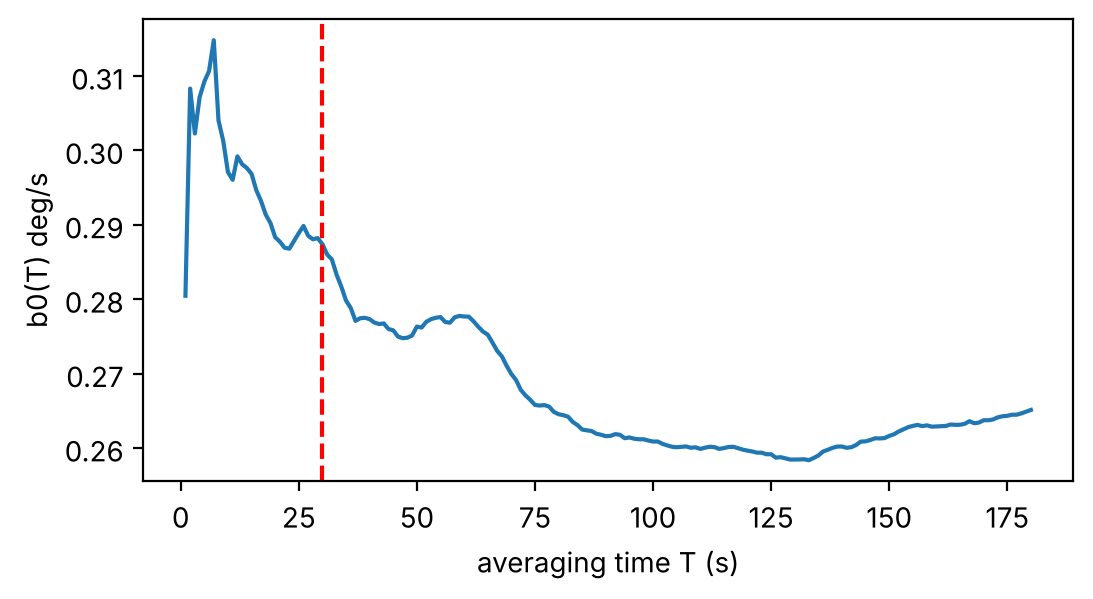

In [2]:
# --- Offset b0: my calibration function ---
def calibrate_gyro(log, T=30, k=3):
    s = log[log.phase=='static']                          # static rows only
    t = (s.t_ms - s.t_ms.iloc[0])/1e3                     # static time in seconds
    w = s.gz_mdps[t<=T].values/1e3                        # first T seconds of rate in deg/s
    m = np.median(w)                                      # robust center of the data
    mad = 1.4826*np.median(abs(w-m))                      # robust standard deviation (median absolute deviation)
    return w[abs(w-m)<k*mad].mean()                       # mean after rejecting outliers beyond k*mad
b0 = calibrate_gyro(d)                                    # offset in deg/s
print(f'Offset b0 = {b0:.4f} deg/s (T = 30 s)')

# --- Bias drift d: slope of 30 s window means ---
wm = [ws[(ts>=a)&(ts<a+30)].mean() for a in range(0,180,30)]   # mean rate in each 30 s window (6 windows)
print(f'Bias drift d = {np.polyfit(np.arange(6)*30+15, wm, 1)[0]*60:+.4f} deg/s/min')  # line fit slope, per minute

# --- Heading drift from integrating the static rate ---
raw, cor = cum(ws,ts), cum(ws-b0,ts)                      # heading without and with b0 subtracted
print(f'Raw heading drift = {np.polyfit(ts,raw,1)[0]*60:.1f} deg/min (b0*60 = {ws.mean()*60:.1f})')  # slope should match b0*60
print('Heading error after b0 removal at 1/2/3 min:', [round(float(np.interp(m,ts,cor)),2) for m in (60,120,179.9)], 'deg')  # leftover error

# --- Noise sigma: std of static rate ---
sig = ws.std(ddof=1)                                      # noise standard deviation in deg/s
print(f'Noise sigma = {sig:.4f} deg/s, R = {sig**2:.5f}, Gaussian test p = {stats.normaltest(ws).pvalue:.2f}')  # R = variance, p>0.05 means Gaussian is plausible

# --- Resolution: smallest output step in the static data ---
print('Resolution: steps alternate 8/9 mdeg/s -> Delta = 0.00875 deg/s')  # 8.75 mdeg/s, shown as 8 or 9 after integer rounding

# --- Plot: offset vs averaging time ---
Tg = np.arange(1,181)                                     # averaging times 1..180 s
plt.figure(figsize=(6,3))
plt.plot(Tg, [ws[ts<=T].mean() for T in Tg])              # b0 computed from the first T seconds
plt.axvline(30, c='r', ls='--')                           # chosen calibration time T = 30 s
plt.xlabel('averaging time T (s)'); plt.ylabel('b0(T) deg/s'); plt.show()

## Rotation run: range, direction, scale factor

Range: max gz = +164.6 / -161.1 deg/s (no clipping seen, so only a lower bound)
Positive direction: CCW
CCW: 1+s = 1.200 -> s = +20.0 %
CW: 1+s = 1.204 -> s = +20.4 %


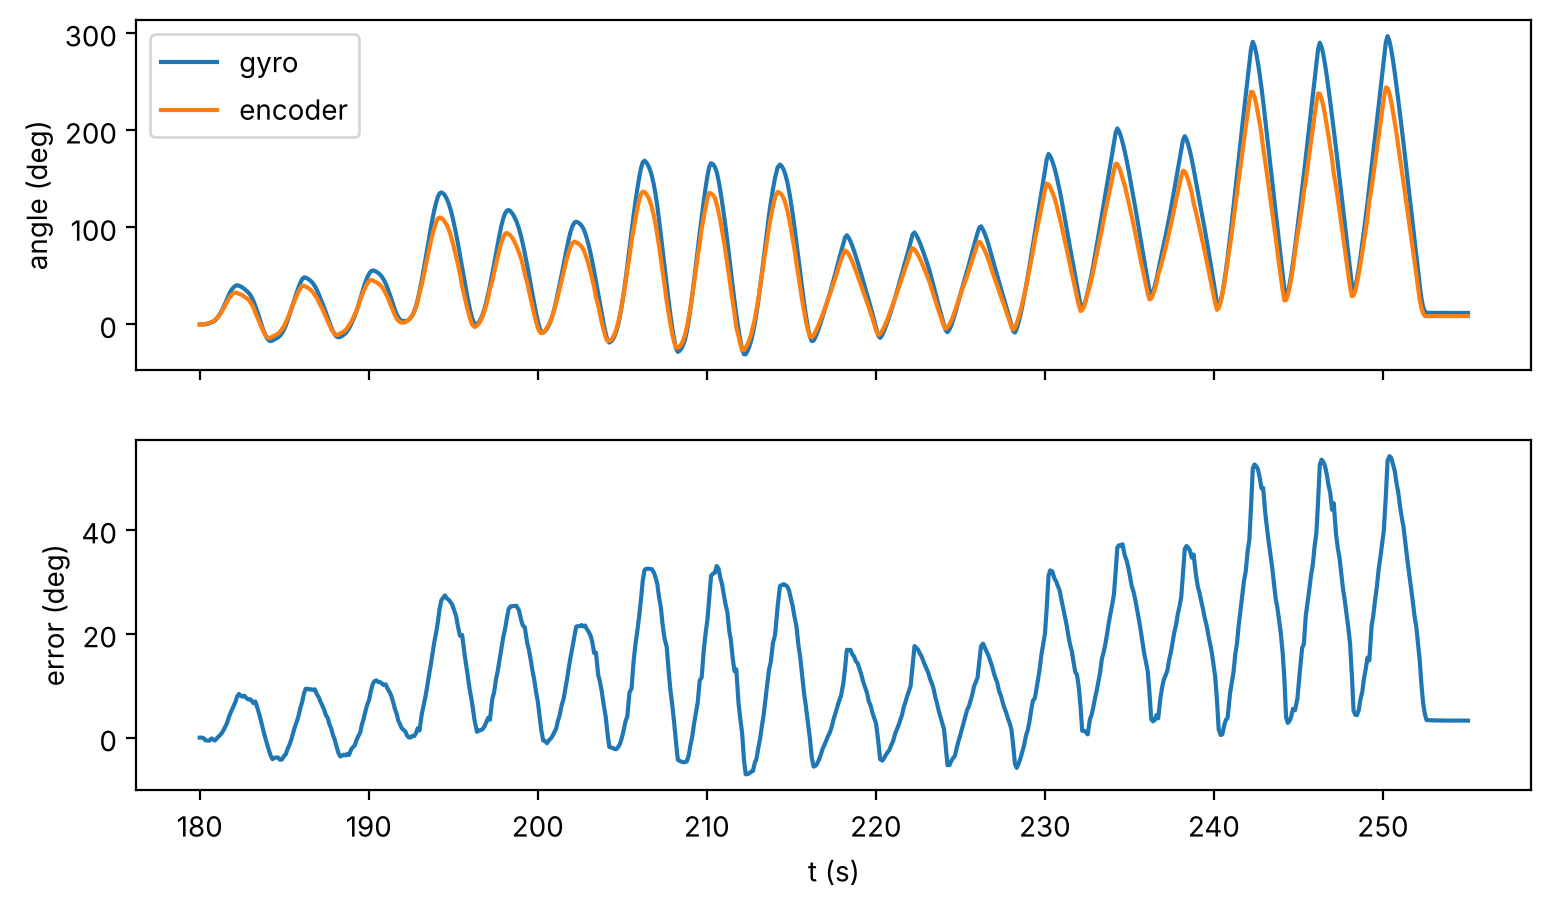

In [3]:
# --- Rotation run data (sin, rect and rest phases) ---
r = d[d.phase!='static'].reset_index(drop=True)           # all non-static rows
t = r.t.values                                            # time in seconds

# --- Encoder angle and gyro angle ---
th_enc = (R_WHEEL/L_TRACK)*(r.encR-r.encL).values         # heading from wheels: (r/L)*(right - left), in deg
th_enc -= th_enc[0]                                       # start at 0
th_gyro = cum(r.w.values-b0, t)                           # heading from gyro: integral of (rate - b0)
w_enc = np.gradient(th_enc, t)                            # rate from encoders in deg/s

# --- Range and direction ---
print(f'Range: max gz = +{d.w.max():.1f} / {d.w.min():.1f} deg/s (no clipping seen, so only a lower bound)')  # largest rates seen
print('Positive direction:', 'CCW' if np.corrcoef(r.w, w_enc)[0,1]>0 else 'CW')  # gyro and encoder rate agree in sign -> CCW

# --- Scale factor: gyro angle vs encoder angle per half-turn ---
sg = np.sign(np.convolve(w_enc,np.ones(3)/3,'same'))      # turn direction from smoothed encoder rate
sg[sg==0] = 1                                             # avoid zero sign
seg = np.cumsum(np.r_[0, sg[1:]!=sg[:-1]])                # segment number, increases at every direction change
rows = []
for s in np.unique(seg):
    i = np.where(seg==s)[0]                               # samples of this half-turn
    if len(i)>2:
        rows.append((sg[i[0]], th_gyro[i[-1]]-th_gyro[i[0]], th_enc[i[-1]]-th_enc[i[0]]))  # direction, gyro angle change, encoder angle change
S = pd.DataFrame(rows, columns=['sign','dg','de'])        # one row per half-turn
S = S[S.de.abs()>5]                                       # ignore tiny segments (under 5 deg)
for name, sgn in (('CCW',1), ('CW',-1)):
    g = S[S['sign']==sgn]                                 # half-turns in this direction
    k = (g.dg*g.de).sum()/(g.de**2).sum()                 # slope through origin = 1 + s
    print(f'{name}: 1+s = {k:.3f} -> s = {(k-1)*100:+.1f} %')  # scale-factor error in percent

# --- Plot: angles and error ---
fig, ax = plt.subplots(2,1,figsize=(9,5),sharex=True)
ax[0].plot(t, th_gyro, label='gyro')                      # gyro heading
ax[0].plot(t, th_enc, label='encoder')                    # encoder heading (reference)
ax[0].set_ylabel('angle (deg)'); ax[0].legend()
ax[1].plot(t, th_gyro-th_enc)                             # error e = gyro - encoder
ax[1].set_ylabel('error (deg)'); ax[1].set_xlabel('t (s)'); plt.show()

## Simulated gyro

In [4]:
# --- Parameters of the gyro model ---
P = dict(b0=b0,                                           # offset, deg/s
         wmax=245.0,                                      # range limit, deg/s (ASSUMED, not measured)
         delta=0.00875,                                   # resolution, deg/s
         sigma=sig,                                       # noise std, deg/s
         s=(S.dg*S.de).sum()/(S.de**2).sum()-1)           # scale-factor error (all half-turns)

# --- Simulated gyro: output = quantize(clip((1+s)*w + b0 + noise)) ---
def gyro_sim(omega_true, t, p=P, seed=0):
    x = (1+p['s'])*omega_true + p['b0']                   # scale factor and offset
    x = x + np.random.default_rng(seed).normal(0, p['sigma'], len(t))  # add Gaussian noise
    x = np.clip(x, -p['wmax'], p['wmax'])                 # saturation at the range limit
    return np.round(x/p['delta'])*p['delta']              # quantization to the resolution step

# --- Compare simulation (driven by encoder rate) with the real log ---
print('RMSE sim vs real: %.1f deg/s' % np.sqrt(np.mean((gyro_sim(w_enc,t)-r.w)**2)))  # difference in deg/s

RMSE sim vs real: 14.1 deg/s
